## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate tsns.countplot(data=df, x='MSZoning', hue='SaleCondition');he correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?



In [112]:
import pandas as pd

In [113]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [114]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
proportions = crosstab_result.div(crosstab_result.sum(axis=1), axis=0)
best_seller_rate = proportions[True]
best_seller_rate.sort_values(ascending=False)

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Name: True, Length: 296, dtype: float64

Grocery, Smart Home Security and Health & Personal care are the categories most prevalent in Best Sellers

In [115]:
from scipy.stats import chi2_contingency


chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

The p-value is 0 (or near 0) suggesting that product category and best-seller status are NOT independent.

In [116]:
from scipy.stats.contingency import association
association(crosstab_result, method="cramer")

0.1222829439760564

The Cramér's V value of 0.1222 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

Text(0.5, 0, 'Category')

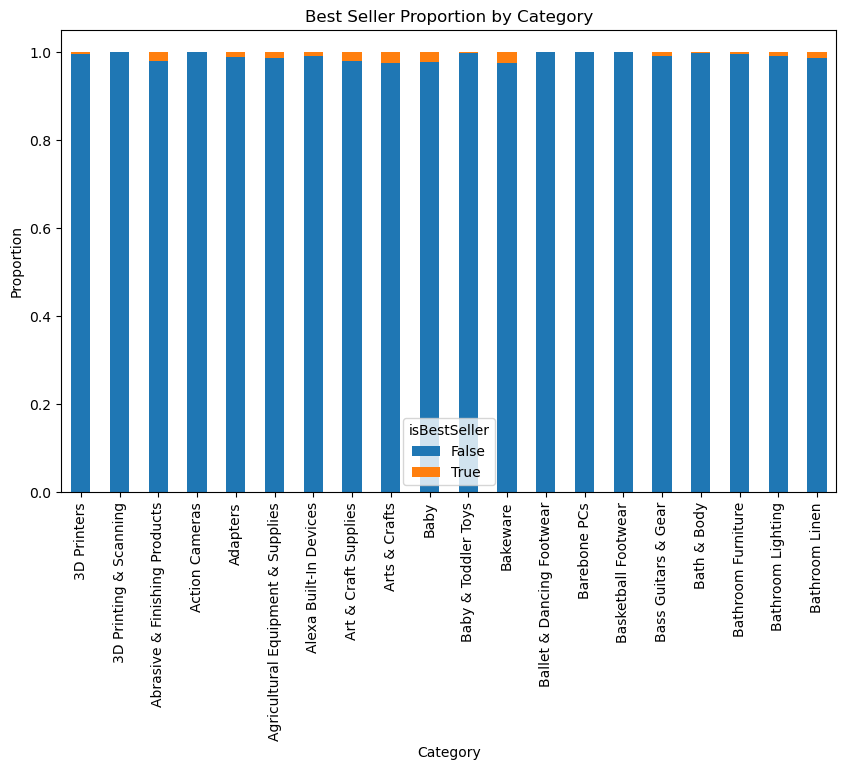

In [134]:
proportions.head(20).plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Best Seller Proportion by Category")
plt.ylabel("Proportion")
plt.xlabel("Category")

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands


In [118]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df= df[(df["price"] >= lower) & (df["price"] <= upper)]




<Axes: xlabel='price'>

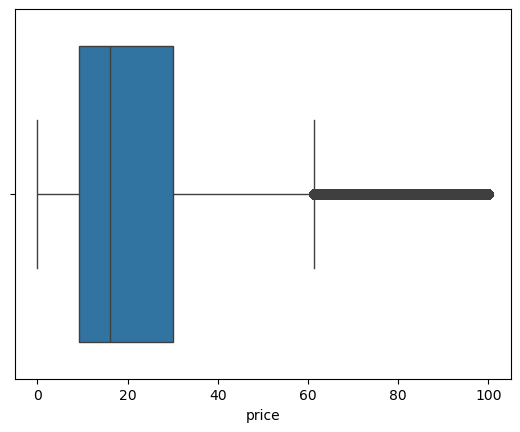

In [119]:
import seaborn as sns
sns.boxplot(x=df["price"])




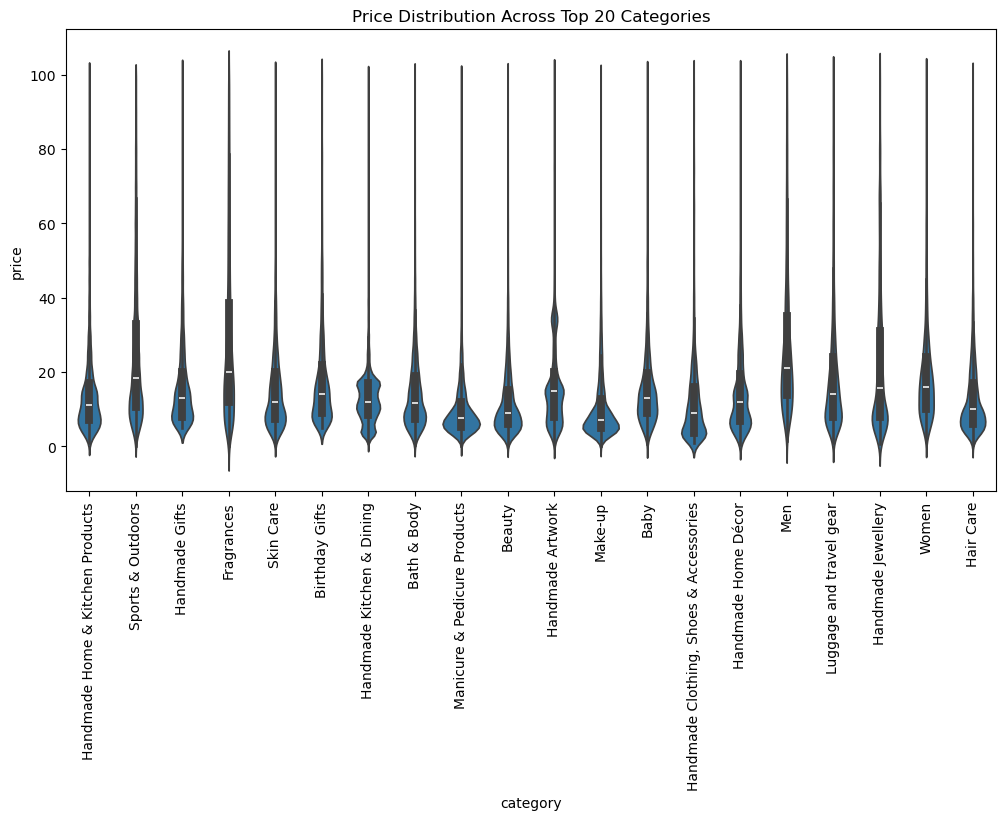

In [120]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get top 20 categories by frequency
top_20_categories = df["category"].value_counts().head(20).index

# Filter dataframe
df_top20 = df[df["category"].isin(top_20_categories)]

# Plot
plt.figure(figsize=(12,6))
sns.violinplot(data=df_top20, x="category", y="price")
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Categories")
plt.show()

In [121]:
df.groupby("category")["price"].agg("median").sort_values(ascending=False)

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

Without filtering by top categories the product category with the highest mean is Motherboards with a median of 52.4

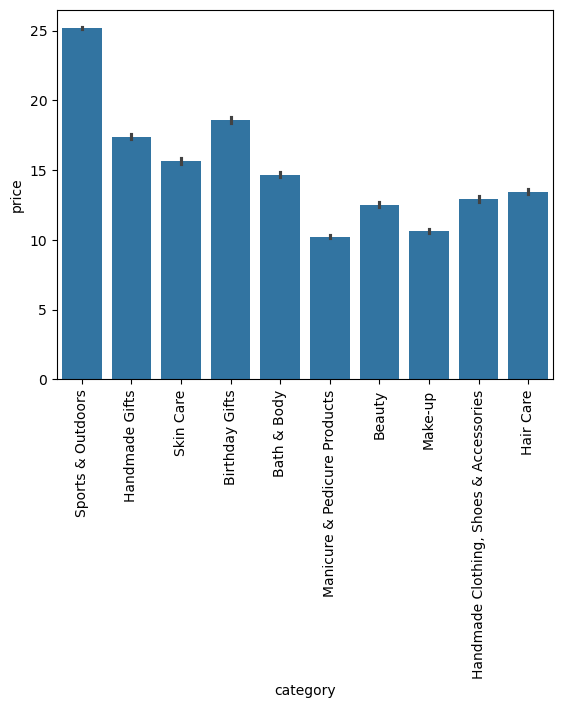

In [122]:
# Get top 10 categories by frequency
top_10_categories = df["category"].value_counts().head(10).index

# Filter dataframe
df_top10 = df[df["category"].isin(top_10_categories)]

sns.barplot(data=df_top10, x="category", y="price")
plt.xticks(rotation=90)
plt.show()

In [123]:
df.groupby("category")["price"].agg("mean").sort_values(ascending=False)

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

Without filtering by top categories the product category with the highest mean is Hockey Shoes with a mean of 46.5

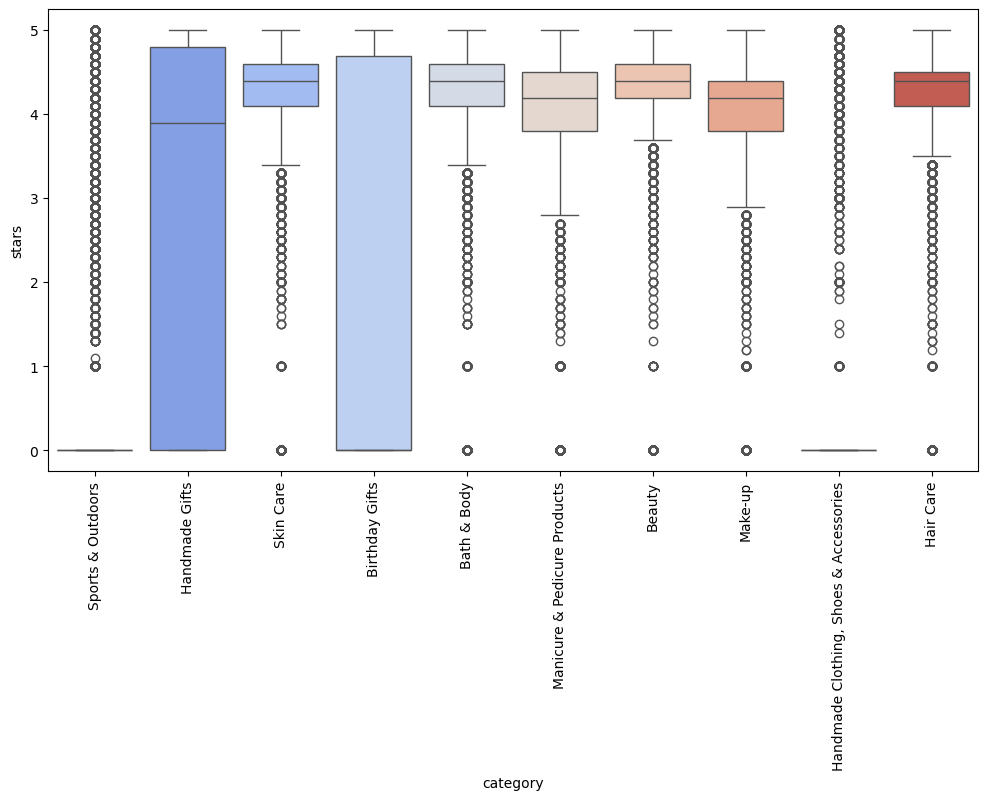

In [124]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm", hue='category', legend=False);
plt.xticks(rotation=90)
plt.show()

In [125]:
df.groupby("category")["stars"].agg("mean").sort_values(ascending=False)

category
Luxury Food & Drink                       4.544140
Grocery                                   4.469414
Laptop Accessories                        4.449600
Health & Personal Care                    4.439549
Arts & Crafts                             4.432942
                                            ...   
Boxing Shoes                              0.160470
Motorbike Handlebars, Controls & Grips    0.134289
Motorbike Electrical & Batteries          0.105697
3D Printing & Scanning                    0.094067
CD, Disc & Tape Players                   0.048834
Name: stars, Length: 296, dtype: float64

Without filtering by top product categories the category with the highest average rating is Luxury Food & Drink with an average rating of 4.54

### INVESTIGATING THE INTERPLAY BETWEEN PRODUCT PRICES AND RATINGS

#### 1. CORRELATION COEFFICIENTS: 

In [127]:
# Calculating the Pearson correlation coefficient between 'stars' and 'price' columns
correlation_pearson = df['price'].corr(df['stars'])
correlation_pearson

np.float64(-0.0776729987818131)

In [128]:
# Calculating the Spearman correlation coefficient between 'stars' and 'price' columns
correlation_spearman = df['price'].corr(df['stars'], method="spearman")
correlation_spearman

np.float64(-0.06679697280768324)

- **Pearson Correlation**: \(-0.0777\)
- **Spearman Correlation**: \(-0.0668\)

**Insights:**

The Pearson correlation (−0.0777) and Spearman correlation (−0.0668) both indicate a very weak negative relationship between product price and rating.
This suggests that price has little to no meaningful influence on rating in the dataset.
The slightly higher Spearman value may indicate minor non-linear effects or the presence of outliers, but the relationship remains extremely weak overall.

#### 2. VISUALISATIONS 

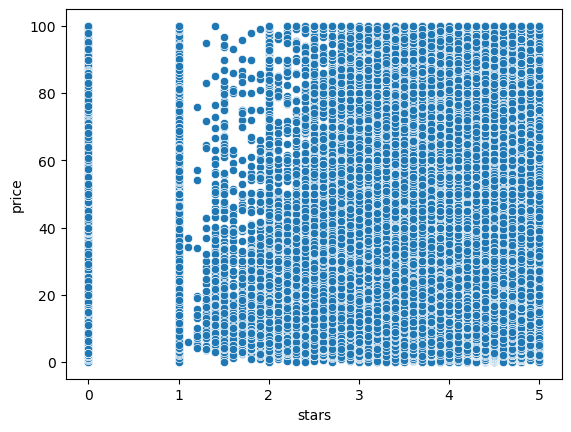

In [129]:
# Plotting a scatter plot to visualize the relationship between 'price' and 'stars' (rating)
sns.scatterplot(data=df, x='stars', y='price');

The scatter plot between stars and price shows a widely dispersed distribution of points without any clear upward or downward trend. This indicates that product ratings do not strongly influence the price. Listings with both low and high prices appear across nearly all rating levels. This visual observation aligns with the Pearson (−0.0777) and Spearman (−0.0668) correlation values, which both suggest a very weak negative relationship between price and rating.

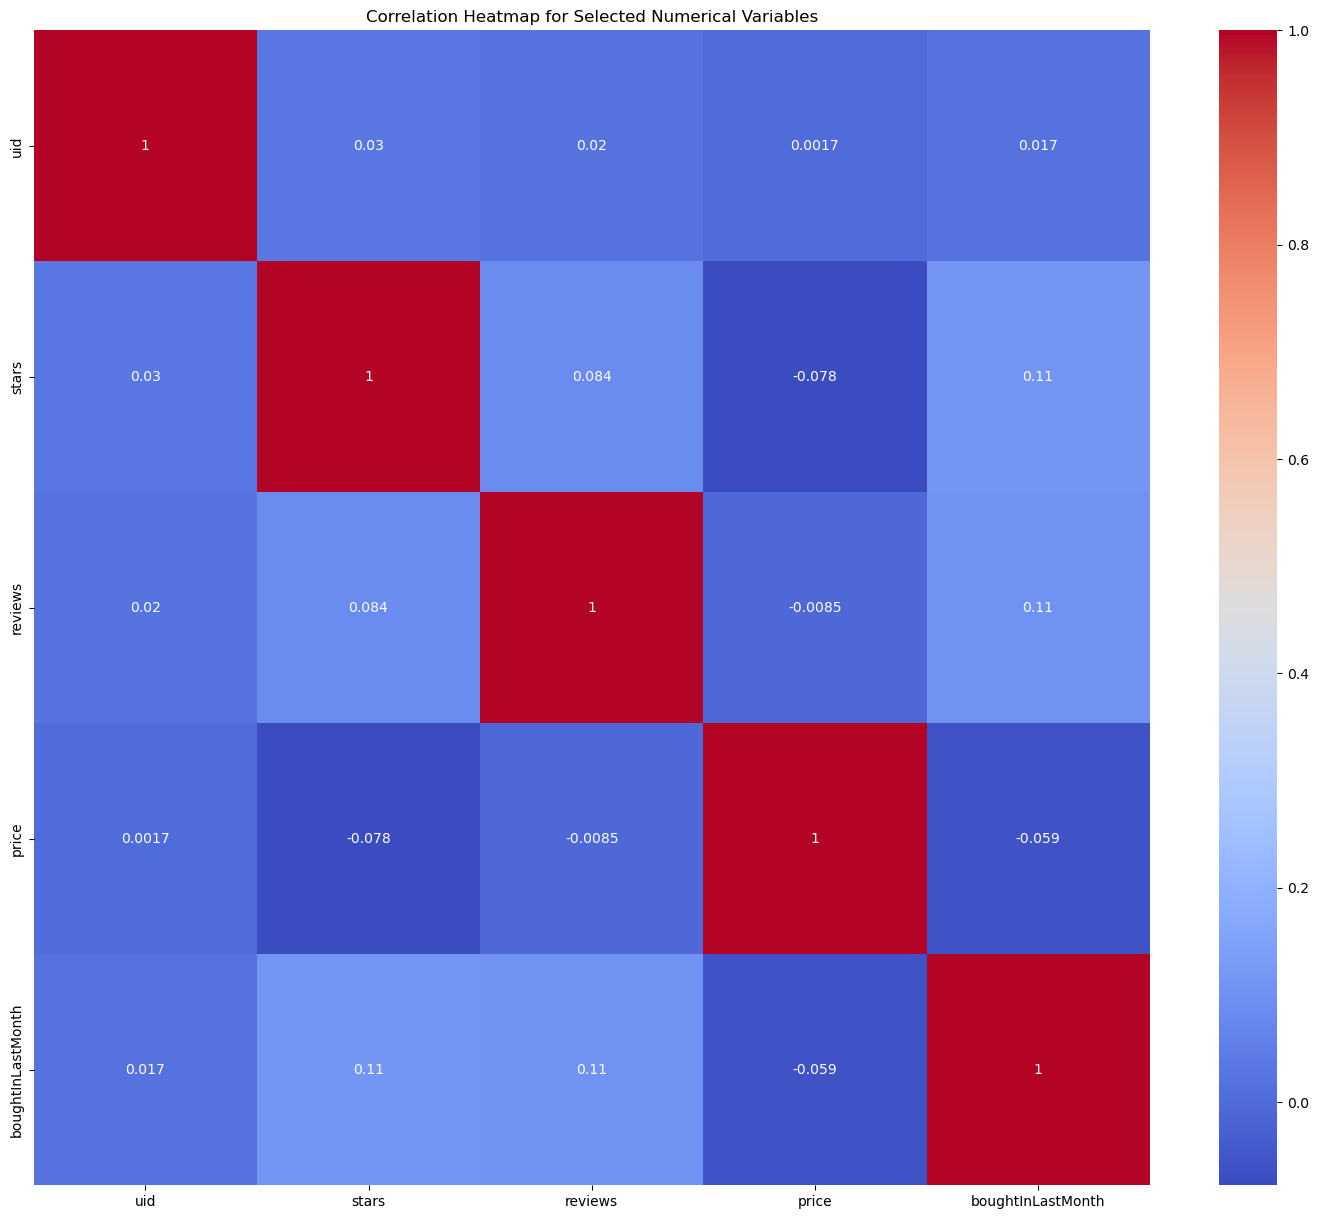

In [130]:
df_numerical = df.select_dtypes(include="number")


correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

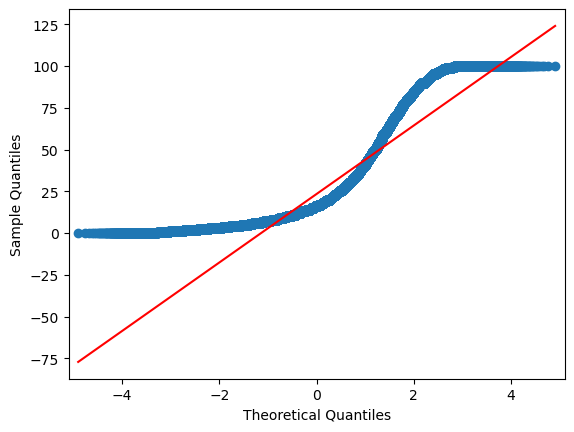

In [131]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df['price'], line='s');

**Lower Tail (Left Side):** The points flatten near 0 and lie above the line. This means there are fewer extremely low values than a normal distribution would expect.

**Upper Tail (Right Side):** The data points bend strongly upward and then flatten near ~100. This indicates many high values relative to a normal distribution. This is characteristic of right skewness (positive skew).

**Middle Section:** The central points curve away from the straight line instead of following it. This indicates non-normal distribution in the main body of the data as well.


**Conclusion:**
The Q–Q plot indicates that the Price variable is not normally distributed. The data points deviate substantially from the reference line, particularly in the tails. The upper tail shows a strong upward deviation, suggesting the presence of high-price values and positive skewness. The lower tail flattens near zero, indicating that the distribution is bounded at the lower end. Overall, the distribution of Price appears to be right-skewed with heavier upper tail values. A log transformation may help reduce skewness and make the distribution closer to normal.

### CONCLUSION AND ANALYSIS: 

This analysis explored how product category, price, and customer ratings relate to product performance and best-seller status. Results show that categories such as Grocery, Smart Home Security & Lighting, and Health & Personal Care have the highest proportion of best-selling products, indicating strong demand in these segments. However, statistical testing reveals that while category influences bestseller likelihood, the strength of this relationship is relatively weak, suggesting that additional factors such as product quality, brand reputation, and marketing likely play a significant role.

The analysis also demonstrates that product category strongly influences pricing, with technology-related categories such as Desktop PCs, Tablets, Graphics Cards, and Motherboards commanding the highest prices, while categories like Arts & Crafts and Office Paper Products operate in lower price ranges. Additionally, product ratings show little correlation with price, indicating that customer satisfaction is not primarily determined by how expensive a product is. Overall, successful products appear to depend on a combination of category positioning, competitive pricing, and strong customer value, rather than any single factor alone.

### BONUS: 

In [133]:
df1 = pd.read_csv("amz_uk_price_prediction_dataset.csv")

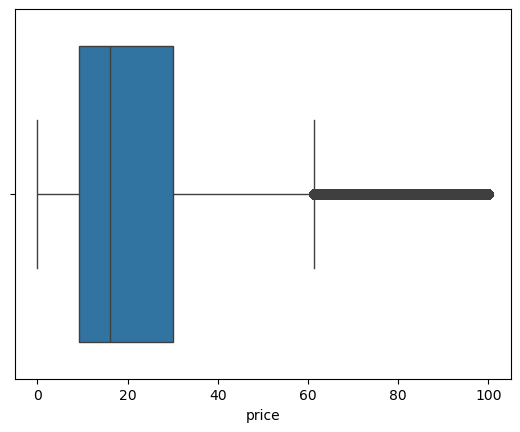

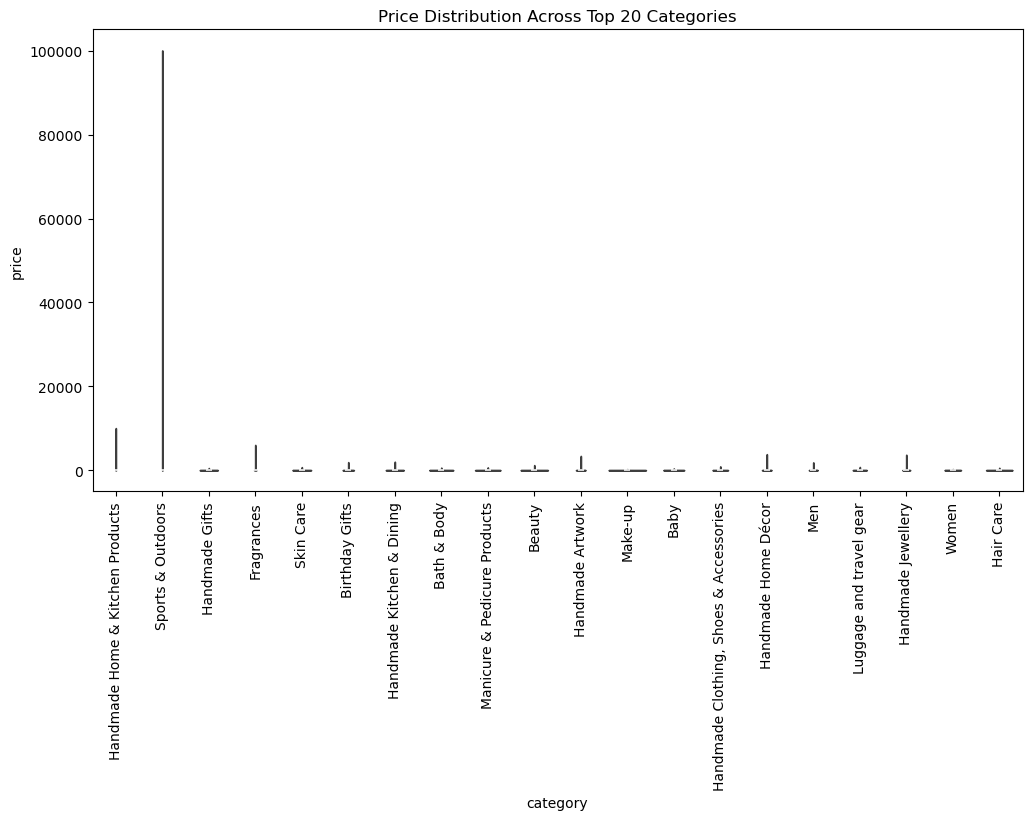

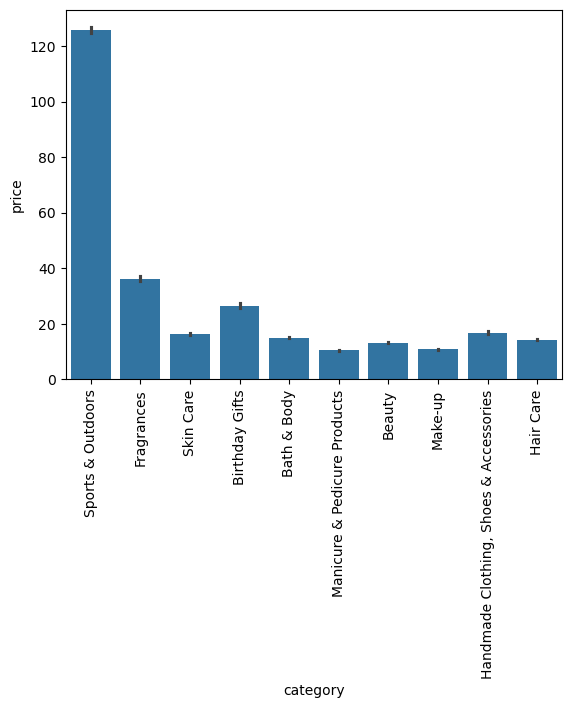

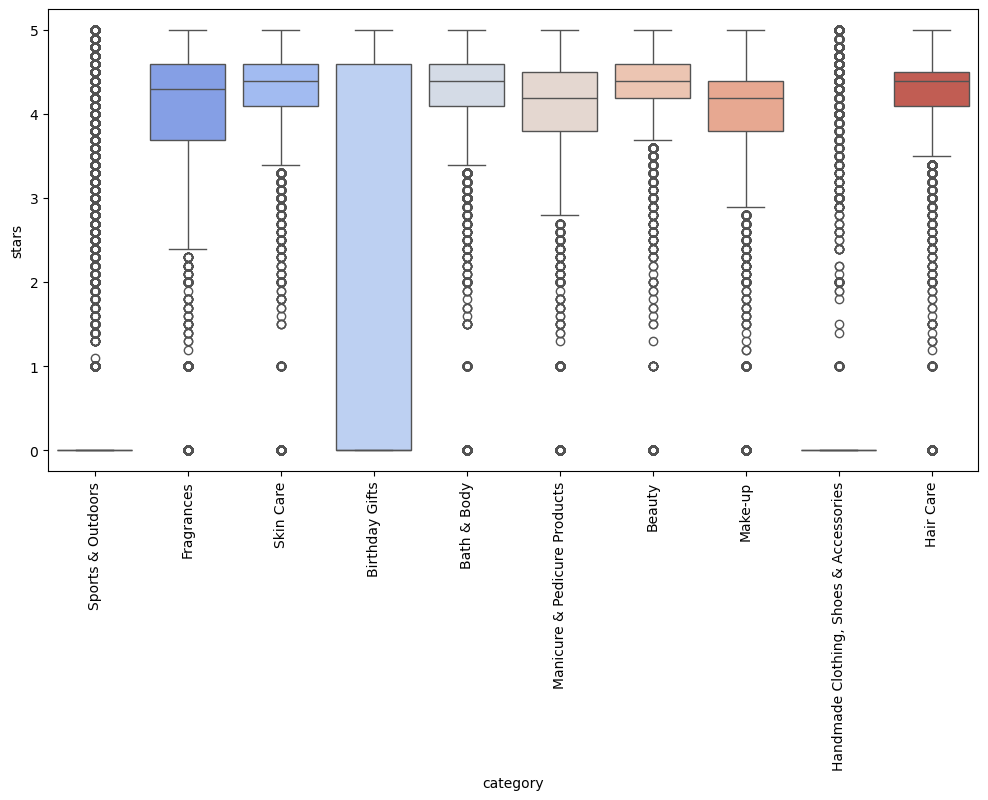

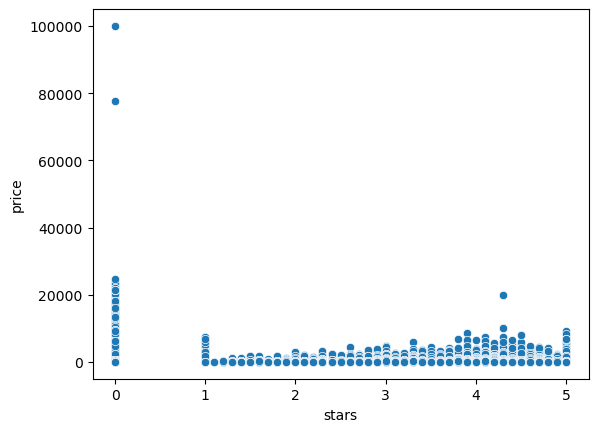

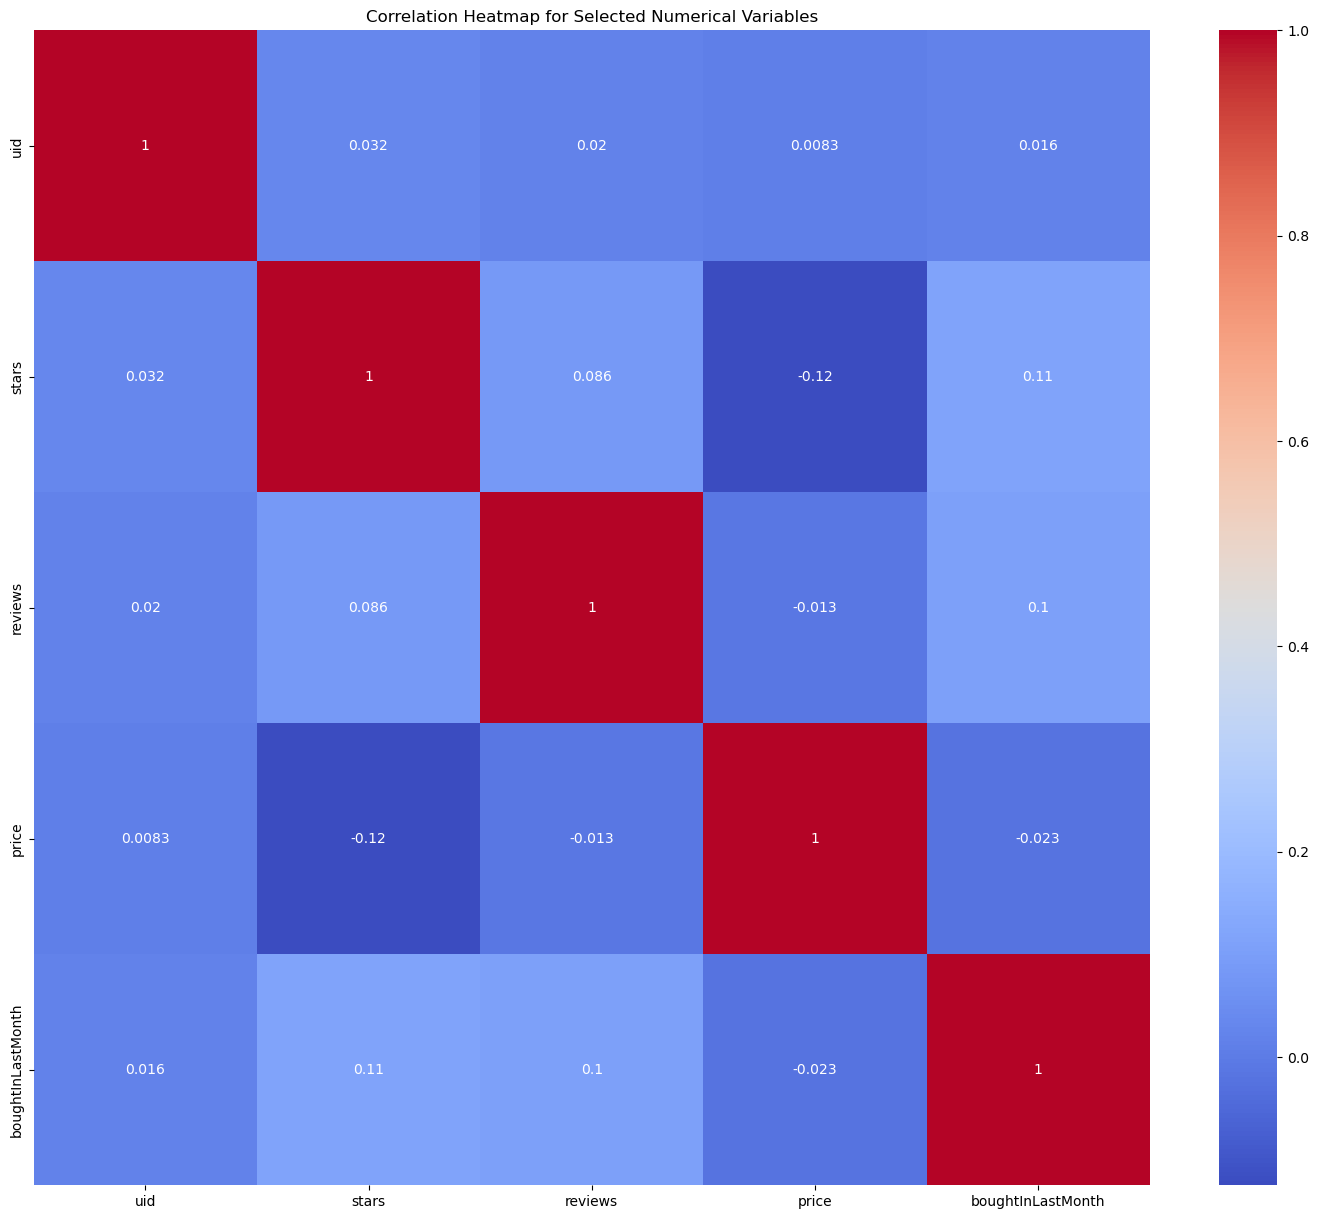

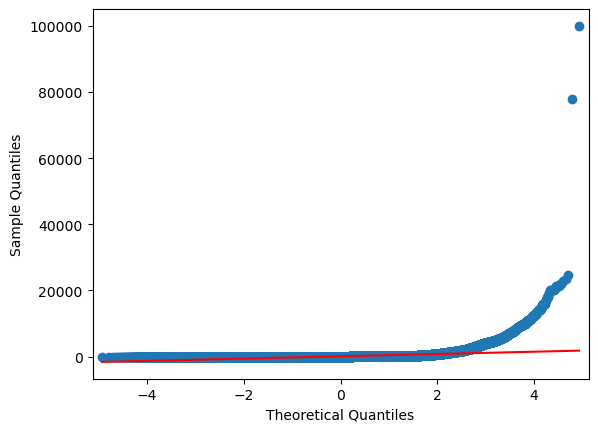

In [135]:
sns.boxplot(x=df["price"])


# Get top 20 categories by frequency
top_20_categories1 = df1["category"].value_counts().head(20).index

# Filter dataframe
df1_top20 = df1[df1["category"].isin(top_20_categories1)]

# Plot
plt.figure(figsize=(12,6))
sns.violinplot(data=df1_top20, x="category", y="price")
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Categories")
plt.show()



df1.groupby("category")["price"].agg("median").sort_values(ascending=False)

# Get top 10 categories by frequency
top_10_categories1 = df1["category"].value_counts().head(10).index

# Filter dataframe
df1_top10 = df1[df1["category"].isin(top_10_categories1)]
sns.barplot(data=df1_top10, x="category", y="price")
plt.xticks(rotation=90)
plt.show()

df1.groupby("category")["price"].agg("mean").sort_values(ascending=False)


plt.figure(figsize=(12,6))
sns.boxplot(data=df1_top10, x='category', y='stars', palette="coolwarm", hue='category', legend=False);
plt.xticks(rotation=90)
plt.show()

df1.groupby("category")["stars"].agg("mean").sort_values(ascending=False)


# Calculating the Pearson correlation coefficient between 'stars' and 'price' columns
correlation_pearson1 = df1['price'].corr(df1['stars'])
correlation_pearson1


# Calculating the Spearman correlation coefficient between 'stars' and 'price' columns
correlation_spearman1 = df1['price'].corr(df1['stars'], method="spearman")
correlation_spearman1


# Plotting a scatter plot to visualize the relationship between 'price' and 'stars' (rating)
sns.scatterplot(data=df1, x='stars', y='price');

df1_numerical = df1.select_dtypes(include="number")


correlation_matrix1 = df1_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix1, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()


# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df1['price'], line='s');